## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


- Conservative = 25.2% survival rate (291/98) & Invasive = 24.2% survival rate (94/388). The point estimate of the ATE is -0.01, so the pump group survived about 1 percentage point less often. From this number alobe, I would rather not get the aortic balloon pump. The difference is small though, so need to bootstrap to determine whether it is real/noise.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

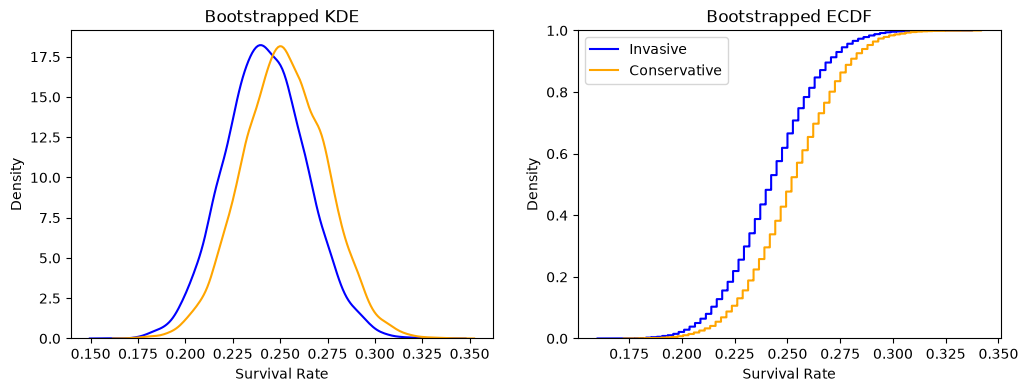

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

The two curves overlap almost completely, with both centered around 24-25% survival. The conservative group sits just slightly to the right. The two groups survival rates are basically the same

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

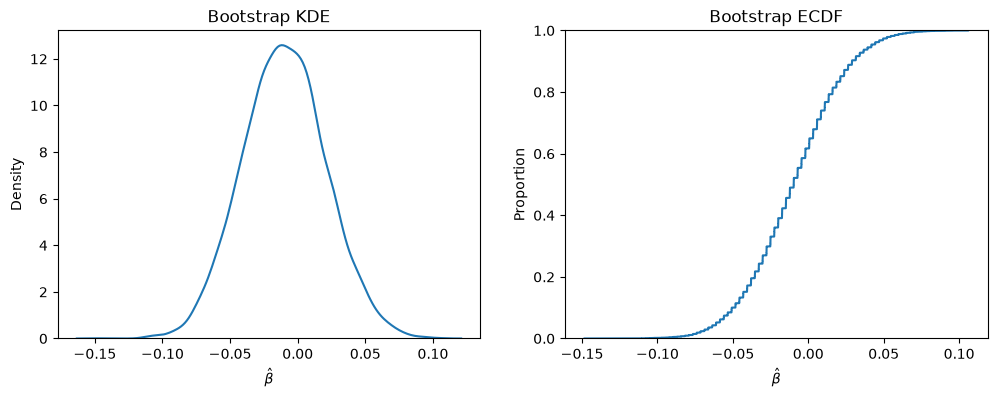

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Yes, it is roughly bell-shaped and centered at ~ -0.01. The range of possible values is about -0.09 to 0.07. This means that the aortic balloon could lower survival by up to ~9 points or raise it up to ~7 points.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06111361  0.04182016]
95% CI: [-0.06887887  0.05208306]
99% CI: [-0.08691911  0.07015742]


Yes, zero is inside all of the confidence intervals, so we would fail to reject the null hypothesis (that the effect is 0) at every level. We reject it at none of the levels. This is because with 0 in the interval it is possible there is ne effect, so we can claim there there's one.

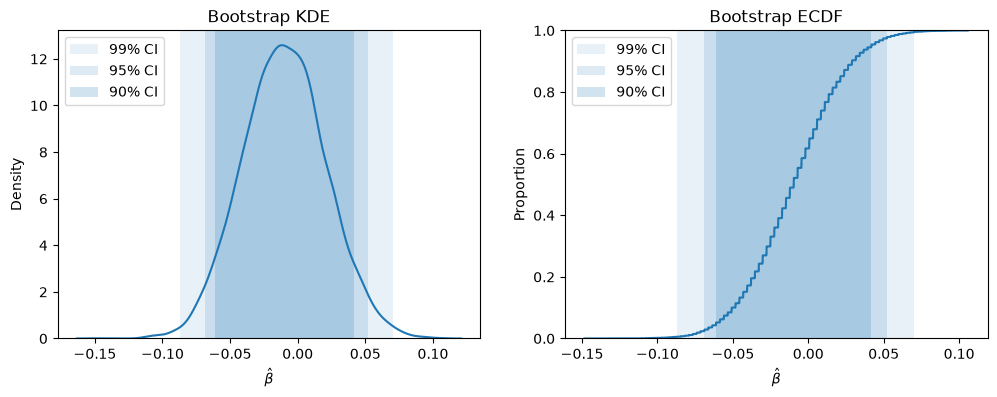

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

We mainly learned that there's no evidence that the aortic balloon pump improves survival since the ATE is slightly negative and every confidence interval includes 0. Since the invasive treatment showed no measurable benefit over conservative treatment, this trial doesn't support using it routinely.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

#### Disclaimer: I didn't use a seed to keep all of the bootstrapping results consistent, but if you rerun the notebook/bootstrap cell as you grade, the conclusions I came to will still hold. I added a seed in my report!

# 2.1

In [14]:
df2 = pd.read_csv('./data/diabetes.csv')
print(df2.head())
print(df2.columns.tolist())

   Unnamed: 0  treatment  outcome
0           1        met  success
1           2       rosi  failure
2           3       rosi  success
3           4  lifestyle  success
4           5        met  success
['Unnamed: 0', 'treatment', 'outcome']


In [15]:
df2 = pd.read_csv('./data/diabetes.csv')
print(pd.crosstab(df2['treatment'], df2['outcome'], margins=True))

outcome    failure  success  All
treatment                       
lifestyle      109      125  234
met            120      112  232
rosi            90      143  233
All            319      380  699


In [16]:
df2['outcome'] = (df2['outcome'] == 'success').astype(int)
print(df2['outcome'].value_counts())

outcome
1    380
0    319
Name: count, dtype: int64


In [17]:
print(df2.groupby('treatment')['outcome'].mean().round(3))

treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: outcome, dtype: float64


rosi had the highest success rate, 61%, then lifestyle, 53%, then met, 48%. The crosstab shows 699 participants split almost evenly across the three groups with 234 lifestyle, 232 metformin, and 233 rosiglitazone. met is the only group with more failures than successses. These are point estimates only though, so the bootstrapping process is needed to be able to tell whether the difference are statistically significant.

## 2.2

In [19]:
R = 10_000

df_met = df2.loc[ df2['treatment'] == 'met',:]
df_rosi = df2.loc[ df2['treatment'] == 'rosi',:]
df_life = df2.loc[ df2['treatment'] == 'lifestyle',:]

outcome_met = []
outcome_rosi = []
outcome_life = []

ate_met_rosi = []
ate_met_life = []
ate_rosi_life = []

for t in range(R):
    df_met_t = df_met.sample(frac=1.0, replace=True)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)
    df_life_t = df_life.sample(frac=1.0, replace=True)

    o_met = df_met_t['outcome'].mean()
    o_rosi = df_rosi_t['outcome'].mean()
    o_life = df_life_t['outcome'].mean()

    outcome_met.append(o_met)
    outcome_rosi.append(o_rosi)
    outcome_life.append(o_life)

    ate_met_rosi.append(o_met - o_rosi)
    ate_met_life.append(o_met - o_life)
    ate_rosi_life.append(o_rosi - o_life)

## 2.3

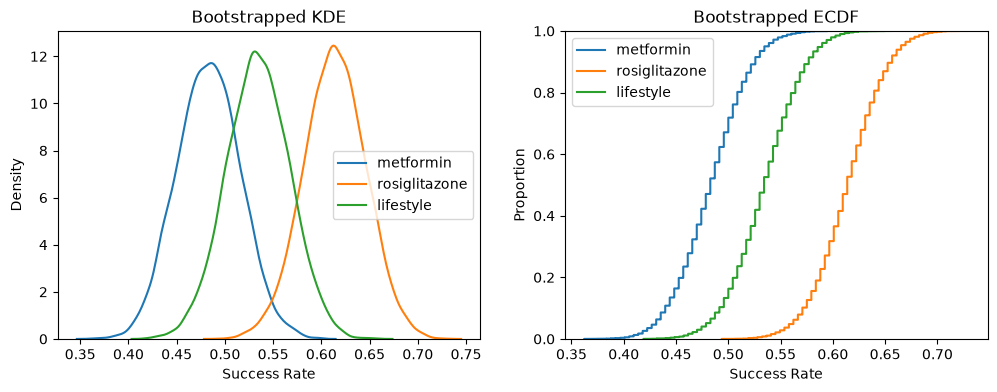

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='metformin', ax=ax[0])
sns.kdeplot(outcome_rosi, label='rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_life, label='lifestyle', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='metformin', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='rosiglitazone', ax=ax[1])
sns.ecdfplot(outcome_life, label='lifestyle', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')

ax[0].legend()
ax[1].legend()
plt.show()

In the KDE plot, all three bootstrapped success rates are bell shaped and about equally spread out (~ +/- 0.06 around their centers). metformin is the furthest left & centered near 0.48, lifestyle is in the middle & centered near 0.53, and rosiglitazone is the furthest right & centered near 0.61. met and lifestyle overlap a lot, as do lifestyle and rosi. This suggests that differences between these pairs may not be significant. met and rosi barely overlap (only a small sliver around 0.55), which sould suggest rosi's higher success rate is probably a real difference rather than random noise.

The ECDF plot shows the same pattern, where curves are shofted left to rught in the same order. rosi's curve sits fully to the right of the metformin curve, which means it has higehr success rates across the whole distribution. The lifestyle cruve falls between the two.

## 2.4

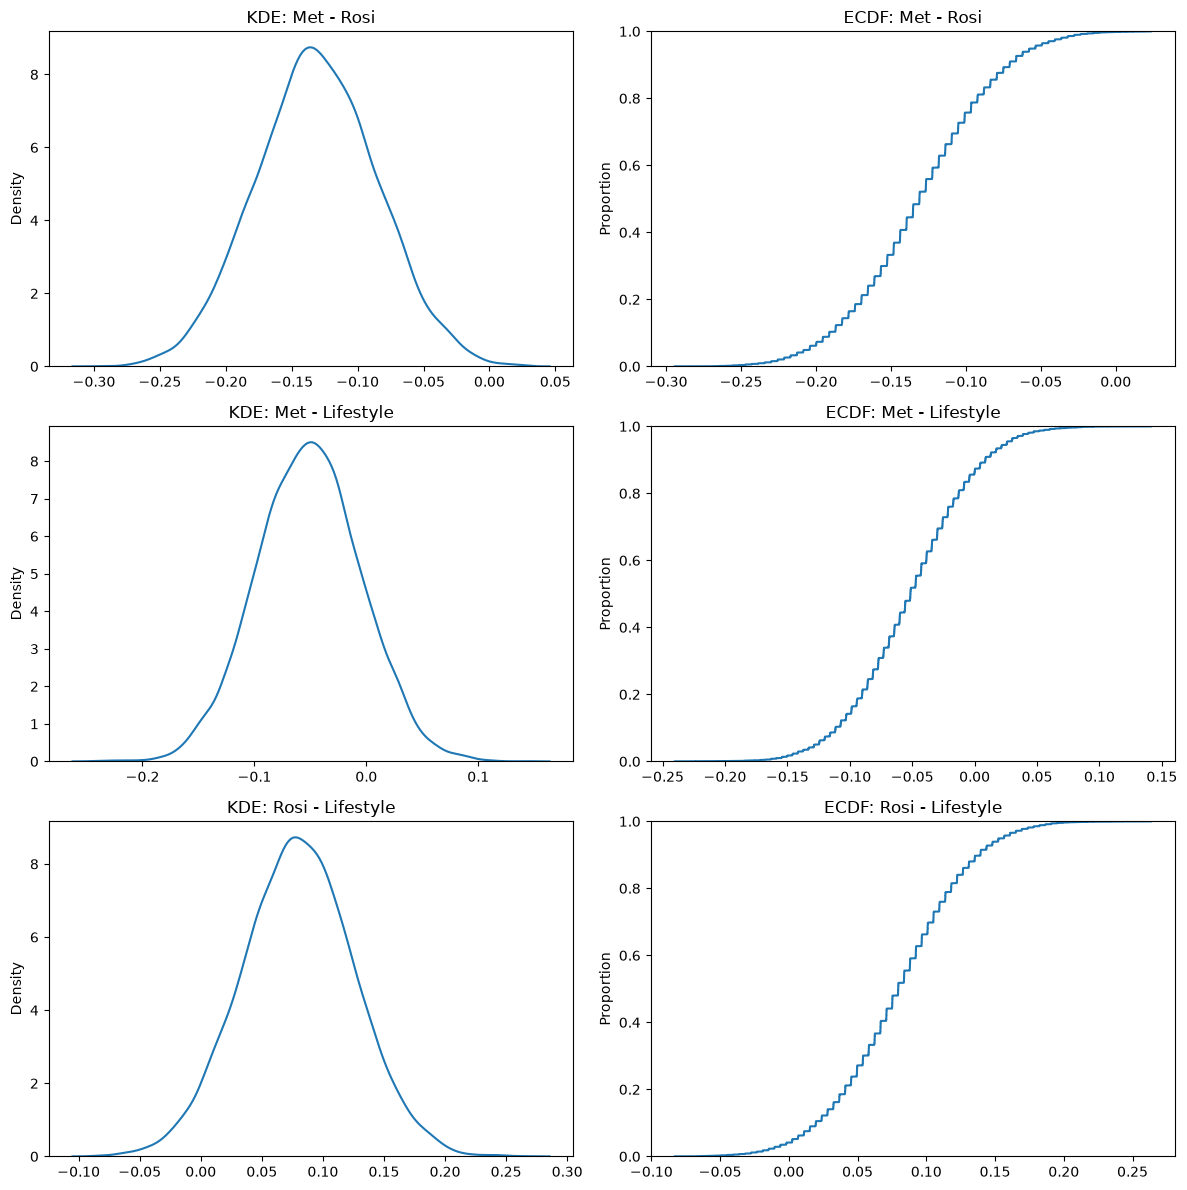

In [21]:
fig, ax = plt.subplots(3, 2, figsize=(12, 12))

#met v rosi
sns.kdeplot(ate_met_rosi, ax=ax[0,0]).set(title='KDE: Met - Rosi')
sns.ecdfplot(ate_met_rosi, ax=ax[0,1]).set(title='ECDF: Met - Rosi')

#met v lifestyle
sns.kdeplot(ate_met_life, ax=ax[1,0]).set(title='KDE: Met - Lifestyle')
sns.ecdfplot(ate_met_life, ax=ax[1,1]).set(title='ECDF: Met - Lifestyle')

#rosi v lifestyle
sns.kdeplot(ate_rosi_life, ax=ax[2,0]).set(title='KDE: Rosi - Lifestyle')
sns.ecdfplot(ate_rosi_life, ax=ax[2,1]).set(title='ECDF: Rosi - Lifestyle')

plt.tight_layout()
plt.show()

## 2.5

In [22]:
print('met - rosi')
print('90% CI:', np.quantile(ate_met_rosi, [.05, .95]))
print('95% CI:', np.quantile(ate_met_rosi, [.025, .975]))
print('99% CI:', np.quantile(ate_met_rosi, [.005, .995]), '\n')

print('met - lifestyle')
print('90% CI:', np.quantile(ate_met_life, [.05, .95]))
print('95% CI:', np.quantile(ate_met_life, [.025, .975]))
print('99% CI:', np.quantile(ate_met_life, [.005, .995]), '\n')

print('rosi - lifestyle')
print('90% CI:', np.quantile(ate_rosi_life, [.05, .95]))
print('95% CI:', np.quantile(ate_rosi_life, [.025, .975]))
print('99% CI:', np.quantile(ate_rosi_life, [.005, .995]))

met - rosi
90% CI: [-0.20423265 -0.05362957]
95% CI: [-0.22121504 -0.04058708]
99% CI: [-0.24707738 -0.01479947] 

met - lifestyle
90% CI: [-0.12835433  0.02582523]
95% CI: [-0.14161601  0.03875626]
99% CI: [-0.16725648  0.07294467] 

rosi - lifestyle
90% CI: [0.00258611 0.15648729]
95% CI: [-0.0104545   0.16949121]
99% CI: [-0.04035078  0.19522395]


The met-rosi comparison is the only difference that is significant at all three CI/levels. Every interval is fully below 0, so metformin's success rate is lower than rosiglitazone's. The estimated gap is ~13 percentage points, and at 95% it's plausible it could range from 4 to 22 points. met vs lifestyle is not significant at any level because 0 is inside every interval, so we can't conclude that the two differ. rosi vs lifestyle is kind of borderline. It is significant at the 90% CI, where the lower bound sits just above 0 at 0.003, but not at the standard 95% interval, where the interval runs from -0.010 to 0.169. rosi looks ~8 points better, but the evidence isn't strong enough to say that with real confidence.

The most effective is rosiglitazone since it has the highest success rate (61%), it beats metformin and points toward beating lifestyle (though this difference isn't significant at 95%). metformin performed worst and didn't outperform lifestyle changes alone. 